# Advanced LLM Scientific Research System — Scientific Literature Retrieval and Evidence Evaluation

**One notebook, 23 core stages plus a real-paper literature pilot.** Literature retrieval and deep paper analysis remain central. Five new real-data workflows cover arXiv/PDF provenance, SciFact model benchmarking, experimental-results and citation networks, evidence-grounded LLM generation, and QASPER/human review.

The initial notebook cells provide a reproducible **synthetic smoke test**, not scientific results. Real external downloads, expensive models, and API calls are strictly opt-in; missing evidence is shown as missing, not scored.

Run this notebook from the full v15 project (including `src/`, `data/` and `PROJECT_BUILD.json`). The first code cell rejects outdated installations.


In [1]:
# v15 project bootstrap: only a complete, matching repository may be imported.
# For a standalone downloaded notebook, use the separate v15 portable release.
from pathlib import Path
from IPython.display import display
import importlib
import json
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESEARCH_QUESTION = 'How do LSTM and Transformer methods compare in time-series forecasting?'
EXPECTED_PROJECT_VERSION = '15.0.0'
REQUIRED_PROJECT_FILES = (
    'PROJECT_BUILD.json',
    'src/research_intelligence/__init__.py',
    'src/research_intelligence/release_audit.py',
    'src/research_intelligence/official_scifact.py',
    'scripts/run_official_evaluation.py',
    'scripts/run_empirical_study.py',
    'src/research_intelligence/qasper_ollama.py',
    'data/demo/corpus.jsonl',
    'data/literature/curated_real_papers.jsonl',
)

def _project_is_valid(folder):
    folder=Path(folder).expanduser()
    if not all((folder / name).is_file() for name in REQUIRED_PROJECT_FILES):
        return False
    try:
        build=json.loads((folder/'PROJECT_BUILD.json').read_text(encoding='utf-8'))
        return build.get('project_version') == EXPECTED_PROJECT_VERSION
    except (OSError, ValueError):
        return False

cwd=Path.cwd().resolve()
configured=os.environ.get('RESEARCH_INTELLIGENCE_ROOT','').strip()
seeds=([Path(configured)] if configured else []) + [cwd,*cwd.parents]
if os.name=='nt':
    seeds += [Path(r'I:\Potforlio\Advanced LLM Scientific Research System')]
options=[]
for seed in seeds:
    options.extend([seed, seed/'Scientific_Research_Official_Evaluation_v15',
                    seed/'Advanced LLM Scientific Research System'])
ROOT=next((f.resolve() for f in options if _project_is_valid(f)),None)
if ROOT is None:
    raise FileNotFoundError(
        'A complete Scientific Research System v15 project was not found. '
        'Extract the full project ZIP and open notebooks/00_Complete_Scientific_Research_Analysis.ipynb, '
        'or use the separate v15 PORTABLE notebook. Old v12/v13 folders cannot provide v15 modules.')
for _module_name in list(sys.modules):
    if _module_name=='research_intelligence' or _module_name.startswith('research_intelligence.'):
        del sys.modules[_module_name]
source=str((ROOT/'src').resolve())
sys.path[:]=[source]+[p for p in sys.path if p!=source]
importlib.invalidate_caches()
import research_intelligence
assert research_intelligence.__version__==EXPECTED_PROJECT_VERSION, research_intelligence.__file__
from research_intelligence.data import load_corpus
from research_intelligence.retrieval import BM25
from research_intelligence.release_audit import write_release_report
from research_intelligence.observed_results import summarize_observed_results
print('Verified project version:', research_intelligence.__version__)
print('Project root:', ROOT)
print('Code loaded from:', research_intelligence.__file__)
print('Mode: offline demo unless live research is explicitly enabled.')

Verified project version: 15.0.0
Project root: I:\Potforlio\Advanced LLM Scientific Research System
Code loaded from: I:\Potforlio\Advanced LLM Scientific Research System\src\research_intelligence\__init__.py
Mode: offline demo unless live research is explicitly enabled.


### Live research workflow (explicit opt-in)

Turn on `ENABLE_REAL_WORKFLOW` in the next cell to collect real arXiv papers, download the **official** SciFact and QASPER test datasets and run their baseline evaluations. PDF processing and model API calls require separate permission/cost flags. Heavy SPECTER2/BGE-M3/Qwen3 comparisons are opt-in and may download large weights.

**Real data is not bundled.** A successful offline demo does not count as an observed research result. Run the complete **project** folder; the `.ipynb` file alone cannot execute the real pipeline.

In [2]:
# Live research requires an explicit opt-in, network and optional model dependencies.
import subprocess

ENABLE_REAL_WORKFLOW = False
FETCH_REAL_ARXIV = True
RUN_FULL_OFFICIAL_SCIFACT = True
RUN_QASPER_TOKEN_F1_PROXY = False
DOWNLOAD_PDF_FILES = False
CONFIRM_PDF_PROCESSING_RIGHTS = False
BILLABLE_LLM_MODEL_ID = ''
CONFIRM_BILLABLE_LLM_CALLS = False

if ENABLE_REAL_WORKFLOW:
    if DOWNLOAD_PDF_FILES and not CONFIRM_PDF_PROCESSING_RIGHTS:
        raise ValueError('Confirm PDF processing rights before downloading full text.')
    if BILLABLE_LLM_MODEL_ID and not CONFIRM_BILLABLE_LLM_CALLS:
        raise ValueError('Billable LLM inference requires explicit confirmation.')
    if FETCH_REAL_ARXIV:
        command = [sys.executable, str(ROOT/'scripts/execute_real_research.py'),
                   '--arxiv','--max-papers','35']
        if DOWNLOAD_PDF_FILES:
            command += ['--download-pdfs','--confirmed-rights']
        if BILLABLE_LLM_MODEL_ID:
            command += ['--llm-model',BILLABLE_LLM_MODEL_ID,'--confirm-api']
        subprocess.run(command,cwd=ROOT,check=True)
    if RUN_FULL_OFFICIAL_SCIFACT:
        command=[sys.executable,str(ROOT/'scripts/run_official_evaluation.py'),
                 '--download-scifact']
        if RUN_QASPER_TOKEN_F1_PROXY:
            command += ['--download-qasper','--qasper-baseline']
        subprocess.run(command,cwd=ROOT,check=True)
else:
    print('LIVE_WORKFLOW_DISABLED: synthetic demonstration. See the Official SciFact section for exact run commands.')

LIVE_WORKFLOW_DISABLED: synthetic demonstration. See the Official SciFact section for exact run commands.


In [3]:
real_paths = [ROOT / 'data/processed/real_research/arxiv_papers.jsonl',
              ROOT / 'data/processed/arxiv_sample.jsonl']
PAPER_CORPUS_FILE = next((candidate for candidate in real_paths if candidate.is_file()),
                          ROOT / 'data/demo/corpus.jsonl')
corpus = load_corpus(PAPER_CORPUS_FILE)
demo_corpus = load_corpus(ROOT / 'data/demo/corpus.jsonl')
synthetic_flags = [doc.metadata.get('synthetic') is True for doc in corpus]
if any(synthetic_flags) and not all(synthetic_flags):
    raise ValueError('Synthetic and real research documents must not be mixed.')
IS_SYNTHETIC = all(synthetic_flags)
DATA_LABEL = 'SYNTHETIC demo' if IS_SYNTHETIC else 'USER-SUPPLIED corpus'
searcher = BM25(corpus)
print(f'Project root: {ROOT}')
print(f'{DATA_LABEL} | {len(corpus):,} documents | {RESEARCH_QUESTION}')
print('Offline baseline; external LLM and large embedding models require explicit execution.')


Project root: I:\Potforlio\Advanced LLM Scientific Research System
SYNTHETIC demo | 20 documents | How do LSTM and Transformer methods compare in time-series forecasting?
Offline baseline; external LLM and large embedding models require explicit execution.


## 01 · Scientific Literature Retrieval

Retrieve scientific papers for one research question; inspect source IDs and citations. The offline synthesis is **extractive**, not a hosted LLM response.


In [4]:
# Retrieve papers and generate an extractive baseline report.
from research_intelligence.llm import LLMClient
from research_intelligence.research_workflow import research_study
question = RESEARCH_QUESTION
study = research_study(question, corpus, BM25(corpus), LLMClient(), k=8, topic_count=3)
print('Demo mode:',study['data_status'])
print('Papers:',len(study['retrieved_papers']))
print('Generation mode:',study['research_synthesis']['generation_kind'])
print('Extractive preview:',study['research_synthesis']['answer'][:500])


Demo mode: synthetic_software_demo
Papers: 8
Generation mode: offline_extractive_test
Extractive preview: Time-series forecasting compares temporal baselines, recurrent neural networks, and Transformer forecasting architectures across forecast horizons. [source: toy-timeseries]
Transformers use self-attention to combine token representations. Parallel token processing differs from recurrent LSTM updates and can have quadratic attention memory cost. [source: toy-transformer]


In [5]:
# Inspect ranked papers and check citation-ID integrity.
paper_table = pd.DataFrame(study['retrieved_papers'])
if not paper_table.empty:
    display(paper_table[['doc_id', 'title', 'score', 'year', 'url']])
print('Citation ID audit:', study['citation_audit'])
for limitation in study['limitations']:
    print('LIMITATION:', limitation)


,doc_id,title,score,year,url
0,toy-timeseries,SYNTHETIC: Time-series Forecasting Strategies,14.784097,2025,
1,toy-transformer,SYNTHETIC: Transformer Attention Modeling,4.229167,2025,
2,toy-lstm,SYNTHETIC: LSTM Sequence Modeling,3.296282,2025,
3,toy-extraction,SYNTHETIC: Named Entity Extraction from Resear...,2.480445,2025,
4,toy-rag,SYNTHETIC: Retrieval-augmented Language Models,2.170702,2025,
5,toy-cost,SYNTHETIC: Accuracy and Inference Cost Tradeoffs,0.446306,2025,
6,toy-dense,SYNTHETIC: Dense Semantic Search,0.329467,2025,
7,toy-rerank,SYNTHETIC: Cross-Encoder Search Reranking,0.322619,2025,


Citation ID audit: {'attempted_citation_ids': ['toy-timeseries', 'toy-transformer'], 'valid_citation_ids': ['toy-timeseries', 'toy-transformer'], 'invalid_citation_ids': [], 'citation_id_validity_proxy': 1.0, 'claim_support_status': 'unverified_requires_evidence_level_review', 'note': 'A valid document ID does NOT prove the document supports the claim. Inspect exact passages and human-verify important conclusions.'}
LIMITATION: Without PDF passages, abstract-only documents do not establish methodology, numerical results or limitations.
LIMITATION: PDF text extraction may lose tables, equations and alignment; inspect original pages before citing numbers.
LIMITATION: Title/abstract keyword matches are not verified method usage or dataset usage.
LIMITATION: Topics (NMF/LDA) are unsupervised descriptors, not authoritative discipline labels.
LIMITATION: The search-results subset is relevance-ranked and is NOT a representative population time series.
LIMITATION: LLM summaries and self-verifi

## 02 · Corpus EDA & Data Quality

Evaluate document coverage, missing metadata, original-year provenance and duplicate candidates. Corpus counts are not global publication trends.


In [6]:
# Summarize corpus metadata completeness.
from research_intelligence.data import metadata_eda
summary = metadata_eda(corpus)
print(DATA_LABEL, summary)
eda_df = pd.DataFrame([{'id':d.id,'year':d.year,'words':len(d.text.split()),
                        'category':','.join(d.categories),'has_url':bool(d.url)} for d in corpus])
eda_view = eda_df.head().copy()
eda_view['url_status'] = np.where(eda_view['has_url'], 'Provided',
                                  'Not provided (demo)' if IS_SYNTHETIC else 'Missing URL')
display(eda_view.drop(columns=['has_url']))


SYNTHETIC demo {'n_documents': 20, 'mean_abstract_words': 17.75, 'median_abstract_words': 17.0, 'year_counts': {'2025': 20}, 'category_counts': {'recurrent networks': 1, 'transformers': 1, 'forecasting': 1, 'RAG': 1, 'lexical retrieval': 1, 'semantic retrieval': 1, 'hybrid search': 1, 'query expansion': 1, 'reranking': 1, 'factual reliability': 1, 'NLI': 1, 'agents': 1, 'prompting': 1, 'evaluation': 2, 'statistics': 1, 'efficiency': 1, 'topic modeling': 1, 'information extraction': 1, 'scientific research': 1}, 'missing_urls': 20}


,id,year,words,category,url_status
0,toy-lstm,2025,19,recurrent networks,Not provided (demo)
1,toy-transformer,2025,22,transformers,Not provided (demo)
2,toy-timeseries,2025,15,forecasting,Not provided (demo)
3,toy-rag,2025,17,RAG,Not provided (demo)
4,toy-bm25,2025,17,lexical retrieval,Not provided (demo)


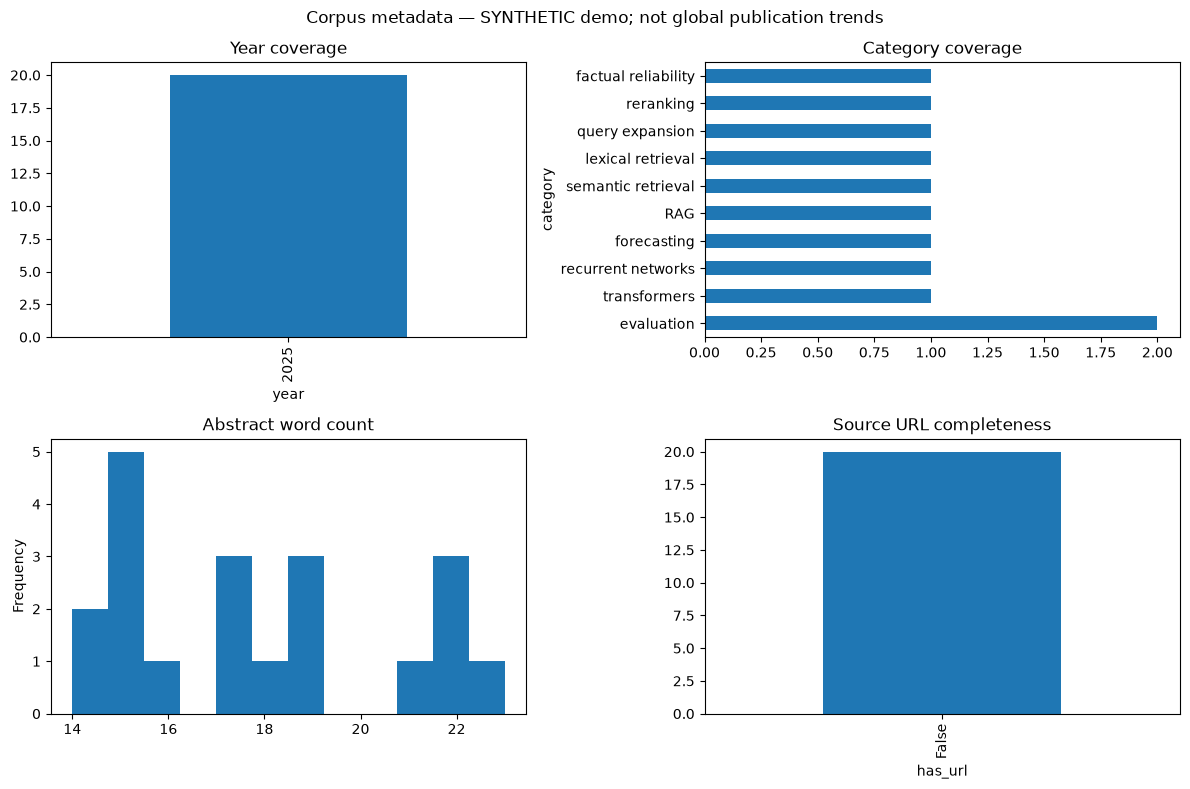

In [7]:
# Visualize corpus coverage; these are input-sample distributions.
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
eda_df['year'].value_counts().sort_index().plot.bar(ax=axs[0,0], title='Year coverage')
eda_df['category'].value_counts().head(10).plot.barh(ax=axs[0,1], title='Category coverage')
eda_df['words'].plot.hist(bins=12, ax=axs[1,0], title='Abstract word count')
eda_df['has_url'].value_counts().plot.bar(ax=axs[1,1], title='Source URL completeness')
fig.suptitle(f'Corpus metadata — {DATA_LABEL}; not global publication trends')
plt.tight_layout(); plt.show()


In [8]:
# Flag duplicate titles and near-duplicate abstracts.
from research_intelligence.deep_diagnostics import audit_corpus
quality, duplicate_candidates = audit_corpus(corpus)
display(pd.DataFrame([{'field':k,'value':str(v)} for k,v in quality.items()]))
if len(duplicate_candidates): display(duplicate_candidates.head(20))
else: print('No duplicate candidates detected at the configured thresholds.')


,field,value
0,documents,20
1,missing_url,20
2,missing_year,0
3,missing_abstract,0
4,synthetic_records,20
5,year_source_counts,{'not_recorded': 20}
6,exact_duplicate_flags,0
7,near_duplicate_threshold,0.92
8,near_duplicate_scope,sampled_candidates_not_confirmed
9,near_duplicate_sampled_documents,20


No duplicate candidates detected at the configured thresholds.


## 03 · Topic Models & Clustering

Compare LDA, NMF and K-Means. Agreement between algorithms does **not** establish topic stability or scientific relevance.


In [9]:
# Fit exploratory LDA and NMF topics to retrieved documents.
from research_intelligence.scientific_analysis import topic_model_comparison
selected = [h.doc for h in searcher.retrieve(RESEARCH_QUESTION, k=min(20,len(corpus)))]
topics = topic_model_comparison(selected, n_topics=3)
print('Topic modeling:', topics['status'], 'documents:',len(selected))
if topics['status'] == 'completed':
    for name, model in topics['models'].items():
        print(name, [(t['topic'],', '.join(t['terms'])) for t in model['topics']])


Topic modeling: completed documents: 16
LDA [(0, 'synthetic, retrieval, cost, research, scientific, attention, lstm'), (1, 'synthetic, search, forecasting, document, retrieval, series, time'), (2, 'judge, evaluation, llm, synthetic, score, labels, model')]
NMF [(0, 'search, retrieval, synthetic, hypothetical, document, cross, ranking'), (1, 'attention, lstm, token, sequential, recurrent, memory, modeling'), (2, 'scientific, research, based, clustering, documents, experimental, claims')]


LDA↔NMF partition agreement (not topic stability or quality): -0.121


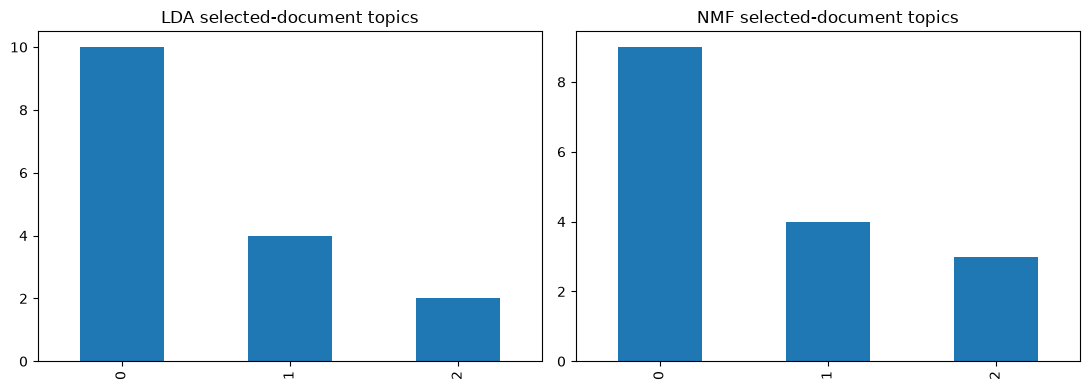

In [10]:
# Compare topic assignments, not scientific validity.
if topics['status']=='completed':
    from sklearn.metrics import adjusted_rand_score
    lda = [r['topic'] for r in topics['models']['LDA']['document_assignments']]
    nmf = [r['topic'] for r in topics['models']['NMF']['document_assignments']]
    print('LDA↔NMF partition agreement (not topic stability or quality):',
          round(adjusted_rand_score(lda,nmf),3))
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for ax,model in zip(axes,['LDA','NMF']):
        counts=pd.Series([r['topic'] for r in topics['models'][model]['document_assignments']]).value_counts()
        counts.sort_index().plot.bar(ax=ax,title=f'{model} selected-document topics')
    plt.tight_layout(); plt.show()


## 04 · Trend and Method Co-occurrence

Contrast full-corpus summaries with top-retrieval selection bias; track topics across publication years when dated data are available.


In [11]:
# Compare year coverage for the full corpus and retrieved subset.
from research_intelligence.scientific_analysis import study_statistics, year_trends, method_cooccurrence
subset = [h.doc for h in searcher.retrieve(RESEARCH_QUESTION, k=min(15,len(corpus)))]
all_trends, selected_trends = year_trends(corpus), year_trends(subset)
print('Year field caution:', all_trends['warning'])
display(pd.DataFrame(all_trends['years']))


Year field caution: Descriptive counts for provided documents only; metadata year may be last-update year. Search-result sampling is not a population publication trend.


,year,n_documents,n_keyword_matches,keyword_match_rate
0,2025,20,None,None


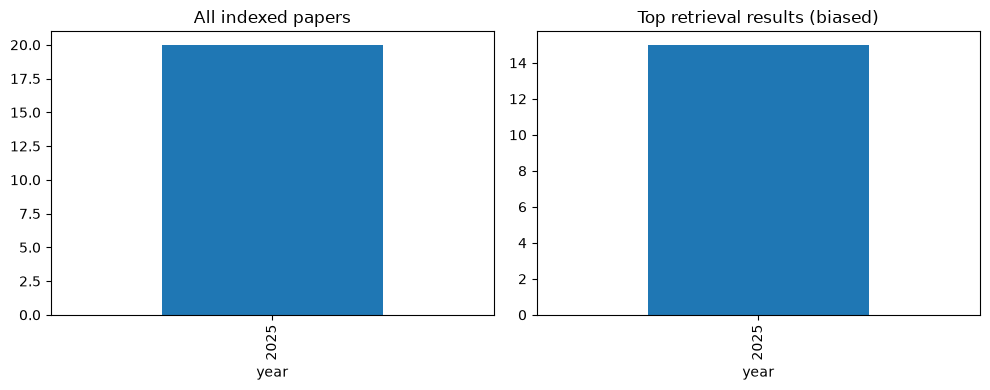

In [12]:
# Plot collection-level and retrieval-biased year distributions.
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,frame,title in zip(axes,[all_trends,selected_trends],['All indexed papers','Top retrieval results (biased)']):
    d=pd.DataFrame(frame['years'])
    if not d.empty: d.plot.bar(x='year',y='n_documents',ax=ax,legend=False,title=title)
plt.tight_layout(); plt.show()


In [13]:
# Count mentions and method co-occurrences within retrieved papers.
stats=study_statistics(subset)
for field in ['models_methods','datasets','metrics']:
    display(pd.DataFrame(stats[field]))
display(pd.DataFrame(stats['method_cooccurrence']))


,term,documents
0,Transformer,2
1,LSTM,2
2,RAG,1
3,BM25,1
4,HyDE,1
5,TF-IDF,1


""


,term,documents
0,Accuracy,1
1,Recall,1
2,Precision,1


,method_a,method_b,co_mentioned_documents
0,LSTM,Transformer,1


In [14]:
# Track topic frequencies only when enough publication years exist.
from research_intelligence.scientific_analysis import topic_evolution_nmf
evolution=topic_evolution_nmf(corpus,n_topics=3)
print('Topic evolution status:',evolution['status'])
if evolution['status']=='completed':
    topic_year_frame=pd.DataFrame(evolution['topic_year_counts'])
    display(topic_year_frame.pivot(index='year',columns='topic',values='documents').fillna(0))
    topic_year_frame.pivot(index='year',columns='topic',values='documents').plot(figsize=(9,4),title='Topic evolution — input corpus, not global science')
    plt.show()
else: print('Not computed:',evolution['reason'])


Topic evolution status: skipped
Not computed: Need >=8 dated documents and >=2 distinct years


## 05 · Evidence-Conscious Paper Comparison

Extract **mentions** of methods, datasets and metrics, without assuming that every mention indicates actual use.


In [15]:
# Extract explicit term mentions; a mention does not prove use.
from research_intelligence.scientific_analysis import compare_documents, extract_explicit_mentions
paper_docs = [h.doc for h in searcher.retrieve(RESEARCH_QUESTION,k=min(8,len(corpus)))]
comparison = pd.DataFrame(compare_documents(paper_docs))
display(comparison[['doc_id','title','methods_mentioned','datasets_mentioned','metrics_mentioned']])


,doc_id,title,methods_mentioned,datasets_mentioned,metrics_mentioned
0,toy-timeseries,SYNTHETIC: Time-series Forecasting Strategies,[Transformer],[],[]
1,toy-transformer,SYNTHETIC: Transformer Attention Modeling,"[LSTM, Transformer]",[],[]
2,toy-lstm,SYNTHETIC: LSTM Sequence Modeling,[LSTM],[],[]
3,toy-extraction,SYNTHETIC: Named Entity Extraction from Resear...,[],[],[]
4,toy-rag,SYNTHETIC: Retrieval-augmented Language Models,[RAG],[],[]
5,toy-cost,SYNTHETIC: Accuracy and Inference Cost Tradeoffs,[],[],[Accuracy]
6,toy-dense,SYNTHETIC: Dense Semantic Search,[],[],[]
7,toy-rerank,SYNTHETIC: Cross-Encoder Search Reranking,[],[],[]


In [16]:
# Inspect source snippets behind extracted terms.
for doc in paper_docs[:3]:
    print('---', doc.id, doc.title)
    for kind, matches in extract_explicit_mentions(doc).items():
        for match in matches[:2]:
            print(kind, match['term'], '| excerpt:', match['quote'])


--- toy-timeseries SYNTHETIC: Time-series Forecasting Strategies
models_methods Transformer | excerpt: Time-series forecasting compares temporal baselines, recurrent neural networks, and Transformer forecasting architectures across forecast horizons.
--- toy-transformer SYNTHETIC: Transformer Attention Modeling
models_methods LSTM | excerpt: Parallel token processing differs from recurrent LSTM updates and can have quadratic attention memory cost.
models_methods Transformer | excerpt: SYNTHETIC: Transformer Attention Modeling.
--- toy-lstm SYNTHETIC: LSTM Sequence Modeling
models_methods LSTM | excerpt: SYNTHETIC: LSTM Sequence Modeling.


## 06 · Research Report & Citation Audit

Export one research report from the same retrieval run. Checking that citation IDs exist does not verify scientific claims.


In [17]:
# Export the current retrieval and research report once.
from research_intelligence.research_workflow import export_study
from research_intelligence.reporting import plot_scientific_study

folder = ROOT / 'reports/generated'
filename = 'SYNTHETIC_software_demo' if IS_SYNTHETIC else 'observed_unreviewed_sources'
_, md_path = export_study(study, folder, name=filename)
figures = plot_scientific_study(study, folder / 'figures')
print('Report:', md_path, '| Figures:', len(figures))


Report: I:\Potforlio\Advanced LLM Scientific Research System\reports\generated\SYNTHETIC_software_demo.md | Figures: 5


## 07 · LLM Model Screening

Load planned scenarios and **observed** API results separately. Model IDs in configuration are examples; no provider is called here.


In [18]:
# List planned LLM test configurations, not measured performance.
from research_intelligence.experiments import grid_scenarios
import yaml
spec = yaml.safe_load((ROOT / 'configs/experiment_grid.yaml').read_text())
scenarios = grid_scenarios(spec, 'llm_screening')
display(pd.DataFrame(scenarios))
print('Planned configurations only; no LLM was called.')


,model,prompt,method,agent
0,openai/gpt-4o-mini,zero_shot,bm25,single
1,openai/gpt-4o-mini,few_shot,bm25,single
2,openai/gpt-4o-mini,evidence_first,bm25,single
3,anthropic/claude-sonnet-4-5-20250929,zero_shot,bm25,single
4,anthropic/claude-sonnet-4-5-20250929,few_shot,bm25,single
5,anthropic/claude-sonnet-4-5-20250929,evidence_first,bm25,single
6,gemini/gemini-2.5-flash,zero_shot,bm25,single
7,gemini/gemini-2.5-flash,few_shot,bm25,single
8,gemini/gemini-2.5-flash,evidence_first,bm25,single
9,ollama/qwen2.5:7b,zero_shot,bm25,single


Planned configurations only; no LLM was called.


In [19]:
# Summarize observed LLM runs only when result records exist.
path = ROOT / 'results/llm_screening.jsonl'
exp = pd.read_json(path, lines=True) if path.is_file() and path.stat().st_size else pd.DataFrame()
print('Observed LLM experiment rows:', len(exp))
fields = {'model', 'latency_ms', 'response_format_ok'}
if not exp.empty and fields.issubset(exp.columns):
    cols = [c for c in ('latency_ms', 'cost_usd', 'response_format_ok') if c in exp]
    display(exp.groupby('model')[cols].mean(numeric_only=True).round(3))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    exp.groupby('model')['latency_ms'].median().plot.bar(ax=axes[0], title='Median latency (ms)')
    exp.groupby('model')['response_format_ok'].mean().plot.bar(ax=axes[1], title='JSON compliance')
    plt.tight_layout()
    plt.show()
elif exp.empty:
    print('NOT RUN: No observed LLM results; planned configurations are not benchmarks.')
else:
    print('Incomplete LLM result schema; need model, latency_ms and response_format_ok.')


Observed LLM experiment rows: 0
NOT RUN: No observed LLM results; planned configurations are not benchmarks.


## 08 · Prompt Strategy Analysis

Compare observed prompt results if provided; otherwise run only the explicit synthetic orchestration smoke test.


In [20]:
# Compare recorded prompt strategies without launching API calls.
if not exp.empty and {'model', 'prompt', 'latency_ms', 'response_format_ok'}.issubset(exp.columns):
    prompt_scores = exp.groupby(['model', 'prompt'])[['response_format_ok', 'latency_ms']].mean()
    display(prompt_scores.round(3))
else:
    print('NOT RUN: No compatible measured prompt comparison records.')


NOT RUN: No compatible measured prompt comparison records.


In [21]:
# Smoke-test prompt wiring with the offline extractive client.
from research_intelligence.pipeline import answer_one
from research_intelligence.schema import Query
prompt_question = Query('prompt_smoke', 'How can RAG reduce unsupported claims?')
for strategy in ('zero_shot','structured','evidence_first','self_refine','ensemble'):
    response = answer_one(prompt_question, BM25(demo_corpus), LLMClient(), prompt=strategy)
    print(strategy, len(response.generation.answer), 'characters — synthetic smoke test only')


zero_shot 340 characters — synthetic smoke test only
structured 340 characters — synthetic smoke test only
evidence_first 340 characters — synthetic smoke test only
self_refine 340 characters — synthetic smoke test only
ensemble 340 characters — synthetic smoke test only


## 09 · Retrieval Benchmark & Field Weighting

Compare BM25, **title-weighted BM25**, TF-IDF and optionally heavy dense/hybrid retrievers. Synthetic qrels verify code only. Fix the title weight before test-set evaluation.


In [22]:
# Evaluate lexical retrievers on synthetic relevance judgments.
from research_intelligence.data import load_queries, load_qrels
from research_intelligence.experiments import retrieval_benchmark
from research_intelligence.retrieval import create_retriever, TitleWeightedBM25
from research_intelligence.evaluation import evaluate_retrieval
import time
import json

benchmark_queries = load_queries(ROOT / 'data/demo/queries.jsonl')
benchmark_qrels = load_qrels(ROOT / 'data/demo/qrels.tsv')
smoke = retrieval_benchmark(demo_corpus, benchmark_queries, benchmark_qrels,
                            ['bm25', 'tfidf'], k=5)
try:
    create_retriever('title_bm25', demo_corpus)
    title_scores = retrieval_benchmark(demo_corpus, benchmark_queries, benchmark_qrels,
                                       ['title_bm25'], k=5)
except ValueError as exc:
    if 'Unknown retrieval method: title_bm25' not in str(exc):
        raise
    # Older source versions have the retriever class but not the factory mapping.
    print('Legacy retrieval.py detected; benchmarking TitleWeightedBM25 directly.')
    title_retriever = TitleWeightedBM25(demo_corpus, title_weight=2.5)
    records = []
    for query in benchmark_queries:
        if query.id not in benchmark_qrels:
            continue
        started = time.perf_counter()
        hits = title_retriever.retrieve(query.question, k=5)
        metrics = evaluate_retrieval([hit.doc.id for hit in hits],
                                     benchmark_qrels[query.id], k=5)
        records.append({'query_id': query.id, 'method': 'title_bm25', 'k': 5,
                        'retrieval_latency_ms': (time.perf_counter() - started) * 1000,
                        'retrieved_ids': json.dumps([hit.doc.id for hit in hits]),
                        **metrics})
    title_scores = pd.DataFrame(records)
smoke = pd.concat([smoke, title_scores], ignore_index=True)
print('SYNTHETIC demo benchmark — not real scientific retrieval quality.')
display(smoke.groupby('method')[['precision@5', 'recall@5', 'mrr@5', 'ndcg@5']].mean().round(3))


SYNTHETIC demo benchmark — not real scientific retrieval quality.


,precision@5,recall@5,mrr@5,ndcg@5
method,,,,
bm25,0.46,0.833,1.00,0.857
tfidf,0.44,0.783,0.95,0.809
title_bm25,0.48,0.867,1.00,0.879


In [23]:
# Inspect which judged papers were missed by each retriever.
from research_intelligence.deep_diagnostics import benchmark_alignment_audit, retrieval_failure_analysis
alignment = benchmark_alignment_audit(demo_corpus,benchmark_queries,benchmark_qrels)
print('Synthetic qrels/data alignment:',alignment)
failures = retrieval_failure_analysis(smoke,benchmark_queries,benchmark_qrels,k=5)
failure_view = failures[['query_id','method','difficulty','judged_recall_at_k',
                         'no_judged_positive_at_k','missed_judged_ids']].head(20).copy()
failure_view['retrieval_status'] = failure_view['no_judged_positive_at_k'].map({
    False: '>=1 judged relevant found (not full recall)',
    True: 'No judged relevant found in top-k'})
display(failure_view.drop(columns=['no_judged_positive_at_k']))
print('Top-k with NO judged positive:', int(failures['no_judged_positive_at_k'].sum()),
      'out of', len(failures), 'synthetic query-method pairs')
print('This example is SYNTHETIC. Real paper-search error analysis requires a frozen evaluated test set.')


Synthetic qrels/data alignment: {'corpus_documents': 20, 'queries': 10, 'judged_queries': 10, 'unknown_qrel_query_ids': [], 'unknown_qrel_doc_ids': [], 'queries_without_qrels': 0, 'judged_pairs': 28, 'interpretation': 'Checks identifier coverage only; qrels may be incomplete'}


,query_id,method,difficulty,judged_recall_at_k,missed_judged_ids,retrieval_status
0,q1,bm25,toy,1.000000,[],>=1 judged relevant found (not full recall)
1,q2,bm25,toy,0.666667,[toy-rrf],>=1 judged relevant found (not full recall)
2,q3,bm25,toy,1.000000,[],>=1 judged relevant found (not full recall)
3,q4,bm25,toy,1.000000,[],>=1 judged relevant found (not full recall)
4,q5,bm25,toy,0.333333,"[toy-cost, toy-dense]",>=1 judged relevant found (not full recall)
5,q6,bm25,toy,1.000000,[],>=1 judged relevant found (not full recall)
6,q7,bm25,toy,0.333333,"[toy-cost, toy-rag]",>=1 judged relevant found (not full recall)
7,q8,bm25,toy,1.000000,[],>=1 judged relevant found (not full recall)
8,q9,bm25,toy,1.000000,[],>=1 judged relevant found (not full recall)
9,q10,bm25,toy,1.000000,[],>=1 judged relevant found (not full recall)


Top-k with NO judged positive: 0 out of 30 synthetic query-method pairs
This example is SYNTHETIC. Real paper-search error analysis requires a frozen evaluated test set.


In [24]:
# Compare per-query changes in ranking quality.
ndcg_by_query = smoke.pivot_table(index='query_id', columns='method', values='ndcg@5', aggfunc='first')
if {'bm25', 'title_bm25'}.issubset(ndcg_by_query.columns):
    delta = (ndcg_by_query['title_bm25'] - ndcg_by_query['bm25']).rename('title_minus_bm25')
    query_delta = pd.DataFrame({'query_id': delta.index, 'delta_ndcg@5': delta.values})
    query_delta['comparison'] = np.select([query_delta['delta_ndcg@5'] > 1e-9,
                                           query_delta['delta_ndcg@5'] < -1e-9],
                                          ['Improved', 'Worsened'], default='Unchanged')
    display(query_delta.sort_values('delta_ndcg@5'))
    print('Synthetic comparison only; repeat with held-out real paper queries.')
else:
    print('Need paired BM25 and title_bm25 results.')


,query_id,delta_ndcg@5,comparison
2,q2,0.000000,Unchanged
7,q7,0.000000,Unchanged
6,q6,0.000000,Unchanged
4,q4,0.000000,Unchanged
9,q9,0.000000,Unchanged
8,q8,0.000000,Unchanged
3,q3,0.016782,Improved
1,q10,0.021086,Improved
0,q1,0.084476,Improved
5,q5,0.104257,Improved


Synthetic comparison only; repeat with held-out real paper queries.


,method,top_k,mean_ndcg,mean_recall
0,bm25,1,0.800,0.367
1,tfidf,1,0.700,0.317
2,title_bm25,1,0.800,0.367
3,bm25,3,0.815,0.700
4,tfidf,3,0.767,0.650
5,title_bm25,3,0.840,0.733
6,bm25,5,0.857,0.833
7,tfidf,5,0.809,0.783
8,title_bm25,5,0.879,0.867
9,bm25,10,0.880,0.933


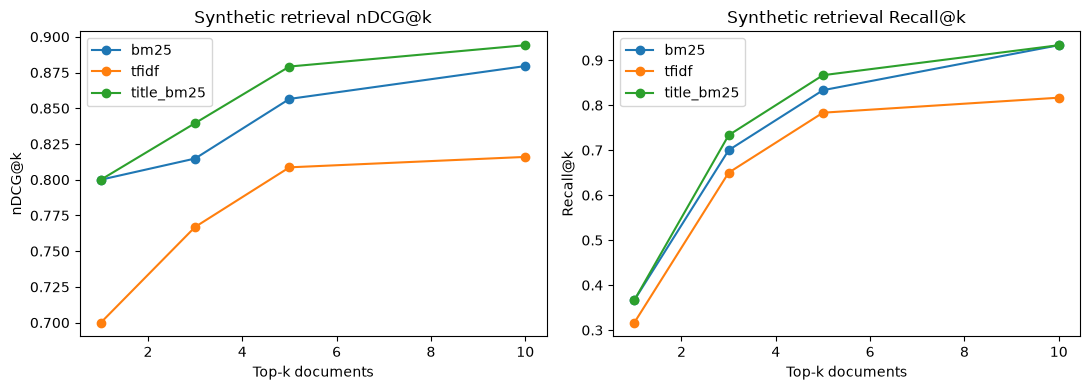

In [25]:
# Test how metric values change with the retrieval cutoff (synthetic labels only).
cutoff_rows = []
for cutoff in (1, 3, 5, 10):
    runs = retrieval_benchmark(demo_corpus, benchmark_queries, benchmark_qrels,
                               ['bm25', 'title_bm25', 'tfidf'], k=cutoff)
    for method, group in runs.groupby('method'):
        cutoff_rows.append({
            'method': method, 'top_k': cutoff,
            'mean_ndcg': group[f'ndcg@{cutoff}'].mean(),
            'mean_recall': group[f'recall@{cutoff}'].mean(),
        })
cutoff_results = pd.DataFrame(cutoff_rows)
display(cutoff_results.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for method, group in cutoff_results.groupby('method'):
    axes[0].plot(group['top_k'], group['mean_ndcg'], marker='o', label=method)
    axes[1].plot(group['top_k'], group['mean_recall'], marker='o', label=method)
for ax, metric in zip(axes, ('nDCG@k', 'Recall@k')):
    ax.set(xlabel='Top-k documents', ylabel=metric, title=f'Synthetic retrieval {metric}')
    ax.legend()
plt.tight_layout()
plt.show()


In [26]:
# Display independently saved SciFact results when available.
real_file = ROOT / 'results/scifact_ir.csv'
if real_file.is_file() and real_file.stat().st_size:
    real_ir = pd.read_csv(real_file)
    available = [m for m in ('ndcg@10','mrr@10','recall@10') if m in real_ir]
    display(real_ir.groupby('method')[available].mean().round(4))
else:
    print('SciFact not evaluated yet; no real retrieval benchmark results.')


SciFact not evaluated yet; no real retrieval benchmark results.


In [27]:
# Compare BM25 versus title-weighted ranking on the current corpus.

base = BM25(corpus).retrieve(RESEARCH_QUESTION, k=8)
weighted = TitleWeightedBM25(corpus, title_weight=2.5).retrieve(RESEARCH_QUESTION, k=8)
comparison_rank = pd.DataFrame({
    'BM25': pd.Series([h.doc.id for h in base]),
    'Title-weighted BM25': pd.Series([h.doc.id for h in weighted]),
})
display(comparison_rank)
print('Observed ranking difference only; relative accuracy needs real relevance judgments.')


,BM25,Title-weighted BM25
0,toy-timeseries,toy-timeseries
1,toy-transformer,toy-lstm
2,toy-lstm,toy-transformer
3,toy-extraction,toy-cost
4,toy-rag,toy-extraction
5,toy-cost,toy-rag
6,toy-dense,toy-dense
7,toy-rerank,toy-rerank


Observed ranking difference only; relative accuracy needs real relevance judgments.


## 10 · Scientific Text Intelligence

Explore TF-IDF clustering and 2D projections. BERTopic/HDBSCAN/SciBERT are optional downloads, not claimed benchmarks.


In [28]:
# Cluster document vectors using a reproducible sample.
from research_intelligence.text_analysis import cluster_documents, year_category_table
text_corpus = corpus if len(corpus)<=1000 else [corpus[i] for i in sorted(np.random.default_rng(42).choice(len(corpus),size=1000,replace=False))]
clusters, info = cluster_documents(text_corpus, n_clusters=4, method='kmeans')
print('Clustering corpus rows:',len(text_corpus),'of',len(corpus));print(info); display(clusters.head(10))


Clustering corpus rows: 20 of 20
{'method': 'kmeans', 'n_clusters': 4, 'noise_docs': 0, 'silhouette': 0.020243306505768936, 'basis': 'tfidf', 'note': 'Cluster labels are exploratory and not ground truth'}


,doc_id,title,cluster,pca_1,pca_2
0,toy-lstm,SYNTHETIC: LSTM Sequence Modeling,3,-0.255894,-0.461824
1,toy-transformer,SYNTHETIC: Transformer Attention Modeling,3,-0.340704,-0.438545
2,toy-timeseries,SYNTHETIC: Time-series Forecasting Strategies,3,-0.207143,-0.232331
3,toy-rag,SYNTHETIC: Retrieval-augmented Language Models,0,-0.065797,0.289251
4,toy-bm25,SYNTHETIC: BM25 Lexical Relevance,2,0.300185,-0.083458
5,toy-dense,SYNTHETIC: Dense Semantic Search,0,0.082733,0.267640
6,toy-rrf,SYNTHETIC: Reciprocal Rank Fusion,1,0.597028,-0.185967
7,toy-hyde,SYNTHETIC: Hypothetical Document Embeddings,0,0.112805,0.310250
8,toy-rerank,SYNTHETIC: Cross-Encoder Search Reranking,0,0.109502,0.207546
9,toy-hallucination,SYNTHETIC: Unsupported Claim Generation,0,-0.105440,0.249294


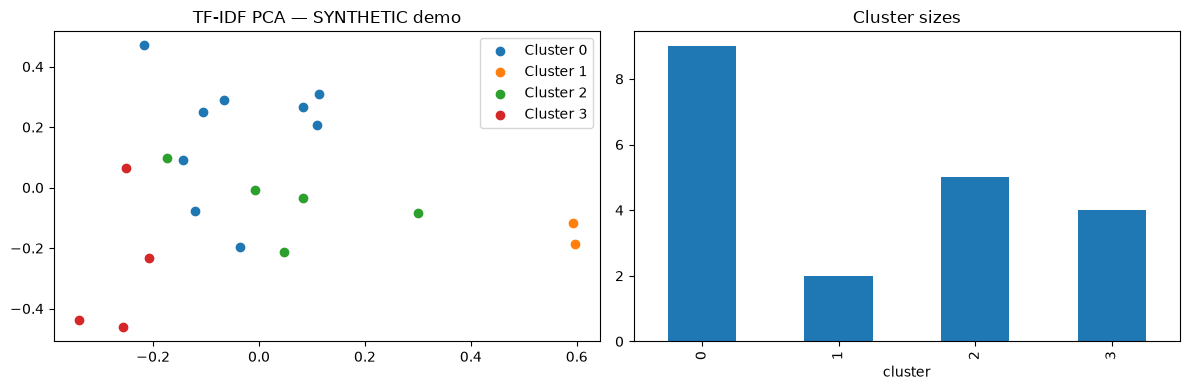

In [29]:
# Inspect exploratory clusters and their sizes.
fig, axs=plt.subplots(1,2,figsize=(12,4))
for label, group in clusters.groupby('cluster'):
    axs[0].scatter(group.pca_1,group.pca_2,label=f'Cluster {label}')
axs[0].legend();axs[0].set_title(f'TF-IDF PCA — {DATA_LABEL}')
clusters.cluster.value_counts().sort_index().plot.bar(ax=axs[1],title='Cluster sizes')
plt.tight_layout();plt.show()


## 11 · Research Agent Architectures

Trace single, planner, verifier and full agent configurations. Without provider and human labels these are workflow smoke tests only.


In [30]:
# Verify agent workflows without treating them as LLM quality tests.
agent_runs = []
for mode in ('single','planner','verifier','full'):
    run = answer_one(Query('agent_smoke','How can scientific claims be verified?'),
                     BM25(demo_corpus), LLMClient(), agent=mode)
    agent_runs.append({'agent':mode,'trace_steps':len(run.trace),'latency_ms':run.elapsed_ms,
                       'api_calls':run.extra['total_api_calls']})
display(pd.DataFrame(agent_runs))
print('SYNTHETIC orchestration only; not a real LLM quality comparison.')


,agent,trace_steps,latency_ms,api_calls
0,single,2,0.1204,0
1,planner,3,0.0854,0
2,verifier,3,0.0685,0
3,full,4,0.0727,0


SYNTHETIC orchestration only; not a real LLM quality comparison.


In [31]:
# Read measured agent latency and cost when available.
path=ROOT/'results/agent_comparison.jsonl'
obs=pd.read_json(path,lines=True) if path.exists() and path.stat().st_size else pd.DataFrame()
if not obs.empty:
    display(obs.groupby('agent')[['latency_ms','cost_usd']].mean(numeric_only=True))
else:
    print('No real agent benchmark has been executed yet.')


No real agent benchmark has been executed yet.


## 12 · Claim Support and Hallucination Review

Report support labels **only** from human-reviewed claim records. Citation-ID checks are not hallucination rates.


In [32]:
# Summarize independent human-reviewed claim labels only.
human_file = ROOT/'data/annotations/human_verified_claims.csv'
claims = pd.read_csv(human_file) if human_file.exists() else pd.DataFrame()
if not claims.empty and 'support_label' in claims:
    display(claims.support_label.value_counts().rename_axis('label').reset_index(name='count'))
    claims.support_label.value_counts().plot(kind='bar',title='Human verified claim labels')
    plt.show()
else:
    print('No actual human claim-level labels exist. See docs/DATA.md; no hallucination rate is computed.')


No actual human claim-level labels exist. See docs/DATA.md; no hallucination rate is computed.


## 13 · ML-Based Error Prediction

Train error classifiers only with adequate human-labeled data; otherwise skip rather than fabricate a predictive result.


In [33]:
# Train error classifiers only with sufficient human-labeled queries.
from research_intelligence.ml_analysis import train_error_classifiers, FEATURES
labels_path = ROOT / 'data/annotations/human_error_labels.csv'
labels = pd.read_csv(labels_path) if labels_path.is_file() else pd.DataFrame()
required = set(FEATURES) | {'human_error_label', 'query_id'}
print('Human-reviewed error labels:', len(labels))
if (len(labels) >= 80 and required.issubset(labels.columns)
        and labels['human_error_label'].nunique() == 2
        and labels['query_id'].nunique() >= 20):
    try:
        scores, artifacts = train_error_classifiers(labels)
        display(scores)
        scores.set_index('model')[['roc_auc', 'average_precision', 'f1_at_0.5']].plot.bar(
            title='Held-out error prediction (human labels)')
        plt.show()
    except ValueError as exc:
        print('SKIPPED: Cannot make a valid group-separated split:', exc)
else:
    print('NOT RUN: Need ≥80 labeled rows, two classes, ≥20 queries and all model features.')


Human-reviewed error labels: 0
NOT RUN: Need ≥80 labeled rows, two classes, ≥20 queries and all model features.


## 14 · Statistical Comparison

Use paired query-level tests and bootstrap intervals. Synthetic effects are illustrative; real effects require independently frozen labels.


In [34]:
# Estimate paired synthetic differences with bootstrap and Wilcoxon.
from research_intelligence.statistics import paired_bootstrap, wilcoxon_paired
paired_scores=smoke.pivot(index='query_id',columns='method',values='ndcg@5').dropna()
if {'bm25','tfidf'}.issubset(paired_scores):
    print('SYNTHETIC bootstrap:',paired_bootstrap(paired_scores['bm25'].tolist(),
                                                  paired_scores['tfidf'].tolist(),n_boot=1000))
    print('SYNTHETIC Wilcoxon:',wilcoxon_paired(paired_scores['bm25'].tolist(),
                                               paired_scores['tfidf'].tolist()))


SYNTHETIC bootstrap: {'mean_delta': 0.047870397138568, 'lower': -0.020468905675929173, 'upper': 0.13648942699574293, 'confidence': 0.95, 'n_queries': 10, 'n_boot': 1000, 'unit': 'paired_query'}
SYNTHETIC Wilcoxon: {'statistic': 2.5, 'p_value': 0.5, 'n_queries': 10}


In [35]:
# Compare real retrieval runs only when paired records exist.
path = ROOT / 'results/scifact_ir.csv'
if path.is_file() and path.stat().st_size:
    real = pd.read_csv(path)
    required = {'query_id', 'method', 'ndcg@10'}
    if required.issubset(real.columns):
        comparison = real.pivot_table(index='query_id', columns='method', values='ndcg@10')
        if {'bm25', 'hybrid'}.issubset(comparison.columns):
            paired = comparison[['hybrid', 'bm25']].dropna()
            if len(paired) >= 2:
                print('Observed SciFact paired bootstrap:', paired_bootstrap(
                    paired['hybrid'].tolist(), paired['bm25'].tolist()))
            else:
                print('NOT RUN: At least two matched query-level observations required.')
        else:
            print('NOT RUN: BM25 and hybrid results are both required.')
    else:
        print('Invalid SciFact schema: expected query_id, method and ndcg@10.')
else:
    print('NOT RUN: No observed SciFact evaluation file.')


NOT RUN: No observed SciFact evaluation file.


## 15 · Full-Text Evidence, QA and Page Anchors

Keep authorized full-text passages linked to source paper IDs and pages. Evaluate QASPER only after importing gold answers **and** predictions.


In [36]:
# Load authorized full-text passages and check corpus alignment.
from research_intelligence.data import read_jsonl
from research_intelligence.fulltext import fulltext_coverage, relevant_passages
from research_intelligence.evidence_research import source_context_matrix, evidence_inventory
fulltext_file = ROOT / 'data/processed/fulltext_passages.jsonl'
REAL_FULLTEXT_AVAILABLE = fulltext_file.is_file() and fulltext_file.stat().st_size > 0
if REAL_FULLTEXT_AVAILABLE:
    passages = read_jsonl(fulltext_file)
elif IS_SYNTHETIC:
    fulltext_file = ROOT / 'data/demo/synthetic_fulltext_passages.jsonl'
    passages = read_jsonl(fulltext_file)
else:
    passages = []
corpus_ids = {doc.id for doc in corpus}
unmatched = sorted({str(p.get('doc_id', '')) for p in passages} - corpus_ids)
if unmatched:
    print(f'WARNING: {len(unmatched)} passage document IDs are not in the active corpus; excluded.')
passages = [p for p in passages if str(p.get('doc_id', '')) in corpus_ids]
print('Full-text status:', 'USER-SUPPLIED' if REAL_FULLTEXT_AVAILABLE else
      'SYNTHETIC EXAMPLE' if passages else 'NO MATCHING PASSAGES')
print('Full-text coverage:', fulltext_coverage(corpus, passages))
if passages:
    display(pd.DataFrame(source_context_matrix(passages)).head(15))


Full-text status: SYNTHETIC EXAMPLE
Full-text coverage: {'corpus_documents': 20, 'parsed_documents': 3, 'missing_full_text': 17, 'unmatched_pdf_ids': [], 'coverage_rate': 0.15, 'scope': 'only files explicitly provided by user'}


,doc_id,section,passages
0,toy-lstm,introduction,1
1,toy-lstm,limitations,1
2,toy-lstm,methods,1
3,toy-lstm,results,1
4,toy-timeseries,introduction,1
5,toy-timeseries,limitations,1
6,toy-timeseries,results,1
7,toy-transformer,discussion,1
8,toy-transformer,future_work,1
9,toy-transformer,introduction,1


In [37]:
# Check page anchors and missing or duplicate evidence IDs.
from research_intelligence.deep_diagnostics import audit_evidence_traceability
evidence_audit = audit_evidence_traceability(passages, corpus)
display(pd.DataFrame([evidence_audit]))


,passages,source_documents_covered,corpus_source_coverage,unmatched_source_ids,duplicate_passage_ids,missing_or_invalid_page,empty_passages,interpretation
0,11,3,0.15,[],0,0,0,Traceability and coverage only; does not estab...


In [38]:
# List lexical evidence candidates, not verified support.
candidate_evidence = relevant_passages(passages, RESEARCH_QUESTION, k=8)
if candidate_evidence:
    display(pd.DataFrame(evidence_inventory(candidate_evidence))[['doc_id','passage_id','page','section','excerpt']])
else: print('No overlapping passages; do NOT fabricate fulltext evidence.')


,doc_id,passage_id,page,section,excerpt
0,toy-timeseries,toy-timeseries#p1s1,1,introduction,SYNTHETIC TEXT: Time-series forecasting benchm...
1,toy-lstm,toy-lstm#p1s1,1,introduction,SYNTHETIC TEXT: LSTM networks use gated state ...
2,toy-lstm,toy-lstm#p2s3,2,results,SYNTHETIC TEXT: Forecasting quality depends on...
3,toy-transformer,toy-transformer#p1s2,1,methods,SYNTHETIC TEXT: We discuss attention-based for...
4,toy-transformer,toy-transformer#p1s1,1,introduction,SYNTHETIC TEXT: Transformer models use attenti...
5,toy-transformer,toy-transformer#p2s3,2,discussion,"SYNTHETIC TEXT: However, model comparisons req..."


In [39]:
# Run the paper analysis with aligned full-text passages.
paper_fulltext_study = research_study(RESEARCH_QUESTION,corpus,BM25(corpus),LLMClient(),
                                      k=8,fulltext_passages=passages,topic_count=3)
fulltext_analysis = paper_fulltext_study['literature_analysis']['fulltext_analysis']
print('Full-text evidence items in report:',len(fulltext_analysis['retrieved_evidence']))
print('Generated answer status:',paper_fulltext_study['research_synthesis']['generation_kind'])
print('Research gap candidates:',len(fulltext_analysis['research_gap_candidates_not_verified']))


Full-text evidence items in report: 6
Generated answer status: offline_extractive_test
Research gap candidates: 3


In [40]:
# Evaluate imported QASPER predictions against gold records.
from research_intelligence.evaluation import evaluate_qasper_predictions
qas_path = ROOT / 'data/processed/qasper_questions.jsonl'
prediction_path = ROOT / 'results/qasper_predictions.jsonl'
if qas_path.is_file() and qas_path.stat().st_size:
    qas = read_jsonl(qas_path)
    print('Imported QASPER questions:', len(qas))
    if qas:
        display(pd.DataFrame(qas).reindex(columns=['paper_id', 'question']).head())
    if prediction_path.is_file() and prediction_path.stat().st_size:
        observed = {str(row['id']): str(row['prediction']) for row in read_jsonl(prediction_path)
                    if 'id' in row and 'prediction' in row}
        display(evaluate_qasper_predictions(observed, qas))
    else:
        print('NOT RUN: Need actual model predictions for QASPER evaluation.')
else:
    print('NOT RUN: QASPER gold questions have not been imported.')


NOT RUN: QASPER gold questions have not been imported.


## 16 · Citation Network & Bibliometrics

Use verified OpenAlex work IDs and explicit citation edges. Network centrality is not research quality.


In [41]:
# Build an observed or explicitly synthetic citation graph.
from research_intelligence.citation_network import network_summary, co_citation_pairs, bibliographic_coupling_pairs
openalex_file=ROOT/'data/raw/openalex_works.jsonl'
REAL_OPENALEX_AVAILABLE=openalex_file.exists() and openalex_file.stat().st_size>0
if not REAL_OPENALEX_AVAILABLE: openalex_file=ROOT/'data/demo/synthetic_openalex_works.jsonl'
work_records=read_jsonl(openalex_file)
network=network_summary(work_records)
print('Network status:', 'USER-SUPPLIED OPENALEX RECORDS' if REAL_OPENALEX_AVAILABLE else 'SYNTHETIC graph only')
print('Nodes / internal edges:',network['n_nodes'],network['n_internal_edges'])
display(pd.DataFrame(network['nodes']).sort_values('pagerank_in_subgraph',ascending=False).head(10))


Network status: SYNTHETIC graph only
Nodes / internal edges: 4 5


,work_id,title,year,internal_citations_received,internal_references_sent,pagerank_in_subgraph,betweenness_in_subgraph,community
2,W9001003,SYNTHETIC node C,2025,3,0,0.470609,0.0,0
1,W9001002,SYNTHETIC node B,2025,2,1,0.254383,0.0,0
0,W9001001,SYNTHETIC node A (NOT indexed in OpenAlex),2025,0,2,0.137504,0.0,0
3,W9001004,SYNTHETIC node D,2025,0,2,0.137504,0.0,0


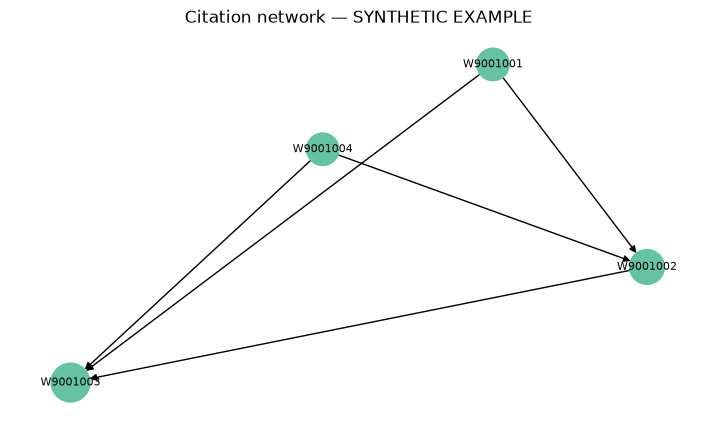

Co-citation pairs: [{'work_a': 'W9001002', 'work_b': 'W9001003', 'co_cited_by_documents': 2}]
Bibliographic coupling pairs: [{'work_a': 'W9001001', 'work_b': 'W9001004', 'shared_references': 2}, {'work_a': 'W9001001', 'work_b': 'W9001002', 'shared_references': 1}, {'work_a': 'W9001002', 'work_b': 'W9001004', 'shared_references': 1}]


In [42]:
# Visualize the partial graph and citation-based similarities.
import networkx as nx
G=nx.DiGraph()
G.add_nodes_from([n['work_id'] for n in network['nodes']])
G.add_edges_from([(e['citing_id'],e['cited_id']) for e in network['edges']])
if G.nodes:
    positions=nx.spring_layout(G,seed=42)
    fig,ax=plt.subplots(figsize=(9,5))
    size_map={n['work_id']:450+700*n['pagerank_in_subgraph'] for n in network['nodes']}
    nx.draw_networkx(G,pos=positions,node_size=[size_map[n] for n in G],font_size=8,arrows=True,ax=ax,
                     node_color=[next(n['community'] for n in network['nodes'] if n['work_id']==id) for id in G],cmap=plt.cm.Set2)
    ax.set_title('Citation network — '+('USER SUPPLIED, PARTIAL' if REAL_OPENALEX_AVAILABLE else 'SYNTHETIC EXAMPLE'))
    ax.axis('off');plt.show()
print('Co-citation pairs:',co_citation_pairs(work_records)[:5])
print('Bibliographic coupling pairs:',bibliographic_coupling_pairs(work_records)[:5])


## 17 · Research Gaps, Contradictions & Robustness

Surface **unverified** candidates and review queues. Query paraphrase overlap is retrieval consistency—not answer accuracy.


In [43]:
# Surface research-gap and contrast candidates for human review.
from research_intelligence.evidence_research import (research_gap_candidates, contradiction_candidates,
    claim_evidence_template, reviewed_support_rate)
gap_candidates = research_gap_candidates(passages)
contrast_candidates = contradiction_candidates(passages)
print('Potential research gaps:',len(gap_candidates),'Contrast language:',len(contrast_candidates))
if gap_candidates:
    gap_view = pd.DataFrame(gap_candidates)
    gap_view['review_status'] = gap_view['verified_research_gap'].map({False: 'PENDING independent review', True: 'Flagged verified'})
    display(gap_view[['doc_id','passage_id','page','quote','review_status']].head())
if contrast_candidates:
    contrast_view = pd.DataFrame(contrast_candidates)
    contrast_view['review_status'] = contrast_view['contradiction_verified'].map({False: 'PENDING independent review', True: 'Flagged verified'})
    display(contrast_view[['doc_id','passage_id','page','quote','review_status']].head())


Potential research gaps: 3 Contrast language: 1


,doc_id,passage_id,page,quote,review_status
0,toy-lstm,toy-lstm#p2s4,2,SYNTHETIC TEXT: Further research is needed on ...,PENDING independent review
1,toy-transformer,toy-transformer#p2s4,2,SYNTHETIC TEXT: Future work should examine sta...,PENDING independent review
2,toy-timeseries,toy-timeseries#p1s3,1,SYNTHETIC TEXT: The evidence remains unclear w...,PENDING independent review


,doc_id,passage_id,page,quote,review_status
0,toy-transformer,toy-transformer#p2s3,2,"SYNTHETIC TEXT: However, model comparisons req...",PENDING independent review


In [44]:
# Export a claim–evidence review queue.
queue_path=ROOT/'results/claim_evidence_review_queue.csv'
review_queue=claim_evidence_template(passages,output_path=str(queue_path))
print('Unreviewed claims to inspect:',len(review_queue),'| saved',queue_path)
print('Verified claim support:', reviewed_support_rate(review_queue))


Unreviewed claims to inspect: 5 | saved I:\Potforlio\Advanced LLM Scientific Research System\results\claim_evidence_review_queue.csv
Verified claim support: {'reviewed_count': 0, 'supported_rate': None, 'reason': 'No independent human-reviewed claim labels'}


In [45]:
# Measure rank overlap under controlled query rewordings.
from research_intelligence.deep_diagnostics import query_rank_stability
from research_intelligence.retrieval import TitleWeightedBM25

# These are controlled examples, not verified equivalent paraphrases.
paraphrases = [
    RESEARCH_QUESTION.replace('compare', 'contrast'),
    RESEARCH_QUESTION.replace(' and ', ' versus '),
]
base_search = BM25(corpus)
field_search = TitleWeightedBM25(corpus, title_weight=2.5)
stability = pd.concat([
    query_rank_stability(retriever, RESEARCH_QUESTION, paraphrases, k=8)
    for retriever in (base_search, field_search)
], ignore_index=True)
if len(stability):
    display(stability[['retriever','variant_query','jaccard_at_k',
                       'top1_same','mean_rank_shift_shared']])
else:
    print('No distinct query paraphrases; edit paraphrases to analyze stability.')


,retriever,variant_query,jaccard_at_k,top1_same,mean_rank_shift_shared
0,bm25,How do LSTM and Transformer methods contrast i...,1.000,True,0.0
1,bm25,How do LSTM versus Transformer methods compare...,0.625,True,0.4
2,title_bm25,How do LSTM and Transformer methods contrast i...,1.000,True,0.0
3,title_bm25,How do LSTM versus Transformer methods compare...,0.625,True,0.4


In [46]:
# Score abstention only on reviewed answerability labels.
from research_intelligence.evaluation import abstention_quality
review_path = ROOT / 'data/annotations/answerability_reviews.csv'
if review_path.is_file():
    reviewed = pd.read_csv(review_path, dtype=str).fillna('')
    accepted = []
    for row in reviewed.to_dict('records'):
        if row.get('answerable','').lower() in {'true','false'} and row.get('abstained','').lower() in {'true','false'}:
            accepted.append({'answerable':row['answerable'].lower()=='true',
                             'abstained':row['abstained'].lower()=='true'})
    print(abstention_quality(accepted))
else:
    print('Abstention requires human-reviewed answerability labels.')


Abstention requires human-reviewed answerability labels.


## 18 · Real Scientific Data: arXiv, DOI Deduplication & Authorized PDFs

Collect live arXiv metadata only when requested, normalize DOI/arXiv identities, and parse PDFs only after local rights confirmation. Never treat an API search sample as the complete scientific literature.

In [47]:
# Real data collection is opt-in and requires network access.
from research_intelligence.real_data_pipeline import normalize_doi, deduplicate_records, save_arxiv_collection
from research_intelligence.data import read_jsonl, load_corpus
RUN_ARXIV_COLLECTION = False
ARXIV_SEARCH = 'all:"time series forecasting"'
REAL_STUDY_DIR = ROOT / 'data/processed/real_research'
REAL_STUDY_CORPUS = REAL_STUDY_DIR / 'arxiv_papers.jsonl'
if RUN_ARXIV_COLLECTION:
    manifest = save_arxiv_collection(ARXIV_SEARCH, REAL_STUDY_CORPUS, count=35)
    print('Real arXiv source:', manifest)
if REAL_STUDY_CORPUS.is_file():
    real_docs = load_corpus(REAL_STUDY_CORPUS)
    print('REAL_ARXIV_API:', len(real_docs), 'unique papers', 'file:', REAL_STUDY_CORPUS)
else:
    real_docs = []
    print('PENDING_REAL_ARXIV: run scripts/run_real_scientific_study.py with --query and --question')

PENDING_REAL_ARXIV: run scripts/run_real_scientific_study.py with --query and --question


In [48]:
# Record identity and duplicate audit on the available real corpus only.
if real_docs:
    raw_real = read_jsonl(REAL_STUDY_CORPUS)
    clean_real, duplicates = deduplicate_records(raw_real)
    duplicate_report = pd.DataFrame(duplicates)
    display(duplicate_report.head(12) if not duplicate_report.empty else pd.DataFrame([{'status':'No exact duplicates detected'}]))
    print('Unique real papers:',len(clean_real), 'DOI coverage:',sum(bool(normalize_doi(d.metadata.get('doi'))) for d in real_docs))
else:
    print('Not evaluated: no real arXiv corpus loaded.')

Not evaluated: no real arXiv corpus loaded.


## 19 · Retrieval & Embedding Benchmark: SciFact

BM25, title-weighted BM25, TF-IDF, SPECTER2, BGE-M3 and Qwen3 embeddings share **one fixed SciFact test set**. Heavy model downloads are off by default. Report failures as missing evaluations, never as zero scores.

In [49]:
# SciFact requires the independent, official BEIR corpus and test qrels.
from research_intelligence.benchmark_real import run_scifact_benchmark, save_benchmark
SCIFACT_DIR = ROOT / 'data/raw/scifact'
RUN_REAL_SCIFACT = False
RUN_HEAVY_EMBEDDINGS = False
baseline_models = ('bm25', 'title_bm25', 'tfidf')
heavy_models = ('specter2', 'bge_m3', 'qwen3')
scifact_run = None
if RUN_REAL_SCIFACT and (SCIFACT_DIR/'corpus.jsonl').is_file():
    requested_models = baseline_models + (heavy_models if RUN_HEAVY_EMBEDDINGS else ())
    scifact_run = run_scifact_benchmark(SCIFACT_DIR, models=requested_models)
    outputs = save_benchmark(scifact_run, ROOT/'results/real_scifact')
    display(pd.DataFrame(scifact_run['summary']))
    display(pd.DataFrame(scifact_run['model_status']))
    from research_intelligence.benchmark_real import paired_model_comparisons
    display(pd.DataFrame(paired_model_comparisons(scifact_run)))
else:
    print('PENDING_SCIFACT: acquire official BEIR scifact data and set RUN_REAL_SCIFACT=True.')
# Show previously measured official data without re-running expensive models.
saved_scifact_summary = ROOT / 'results/real_scifact/scifact_summary.csv'
saved_scifact_status = ROOT / 'results/real_scifact/scifact_model_status.csv'
if saved_scifact_summary.is_file() and saved_scifact_status.is_file():
    print('Saved official SciFact metrics (observed runs only):')
    display(pd.read_csv(saved_scifact_summary))
    display(pd.read_csv(saved_scifact_status))


PENDING_SCIFACT: acquire official BEIR scifact data and set RUN_REAL_SCIFACT=True.


In [50]:
# Plot measured SciFact nDCG@10 only when real results exist.
if scifact_run and scifact_run['summary']:
    measured = pd.DataFrame(scifact_run['summary'])
    ndcg10 = measured[measured['k']==10].dropna(subset=['ndcg'])
    if not ndcg10.empty:
        ax = ndcg10.plot.bar(x='model',y='ndcg',figsize=(9,3),legend=False,ylim=(0,1))
        ax.set_ylabel('Observed SciFact nDCG@10')
        plt.tight_layout();plt.show()
else:
    print('No real model scores plotted; benchmark not run.')

No real model scores plotted; benchmark not run.


## 20 · Deep Scientific Paper Analysis: Experimental Values, Topic Evolution & Citations

Extract traceable metric-value **candidates**, never verified model superiority. Compare numerical results only after human validation, and build OpenAlex networks from exact DOI matches.

In [51]:
# Read real PDF passages generated by the explicit local-rights workflow.
from research_intelligence.deep_paper_analysis import (extract_experiment_values, comparable_experiments,
                                                       topic_evolution_by_year, save_experiment_review_template,
                                                       load_verified_experiments)
from research_intelligence.citation_network import network_summary
REAL_PASSAGES_FILE = REAL_STUDY_DIR/'fulltext_passages.jsonl'
real_passages = read_jsonl(REAL_PASSAGES_FILE) if REAL_PASSAGES_FILE.is_file() else []
experiment_candidates = extract_experiment_values(real_passages)
manual_review_file = REAL_STUDY_DIR/'experiment_review.csv'
if experiment_candidates:
    save_experiment_review_template(experiment_candidates,manual_review_file)
verified_experiments = load_verified_experiments(manual_review_file) if manual_review_file.exists() else []
topic_timeline = topic_evolution_by_year(real_docs) if real_docs else {'status':'no_real_corpus'}
print('Real full-text passages:',len(real_passages), 'unverified value candidates:',len(experiment_candidates))
if experiment_candidates:
    display(pd.DataFrame(experiment_candidates).head(20)[['doc_id','page','metric','observed_value','dataset_candidate','status']])
print('Verified cross-paper comparison groups:',len(comparable_experiments(verified_experiments)))
print('Topic evolution status:',topic_timeline['status'])

Real full-text passages: 0 unverified value candidates: 0
Verified cross-paper comparison groups: 0
Topic evolution status: no_real_corpus


In [52]:
# Citation edges are generated only from actual OpenAlex `referenced_works` fields.
OPENALEX_FILE = REAL_STUDY_DIR/'openalex_works.jsonl'
if OPENALEX_FILE.is_file():
    graph_results = network_summary(read_jsonl(OPENALEX_FILE))
    print('Observed network:',graph_results['n_nodes'],'works /',graph_results['n_internal_edges'],'internal edges')
    display(pd.DataFrame(graph_results['nodes']).head(12))
else:
    print('PENDING_OPENALEX: run the real study CLI with --openalex (exact DOI matching).')
if topic_timeline.get('status')=='completed':
    time_df = pd.DataFrame(topic_timeline['topic_shares'])
    time_df.pivot(index='year',columns='topic',values='share').plot(figsize=(9,3),marker='o')
    plt.ylabel('Corpus share');plt.title('Query-specific arXiv topic evolution');plt.tight_layout();plt.show()

PENDING_OPENALEX: run the real study CLI with --openalex (exact DOI matching).


## 21 · LLM Reasoning & Evidence Verification

LLM calls are disabled by default. Generated claims receive passage citations and are exported for review; the presence of a citation ID does **not** prove the scientific claim is supported.

In [53]:
# Retrieve real page-anchored evidence and keep LLM costs explicitly opt-in.
from research_intelligence.fulltext import relevant_passages
from research_intelligence.llm_verification import (generate_grounded_answer, build_claim_review_queue,
                                                     verify_claims_against_passages,
                                                     save_review_queue)
RUN_REAL_LLM = False
CONFIRM_API_COSTS = False
LLM_MODEL_ID = 'extractive-baseline'  # Set a valid LiteLLM model ID for actual generation.
grounded_evidence = relevant_passages(real_passages,RESEARCH_QUESTION,k=8) if real_passages else []
if RUN_REAL_LLM and LLM_MODEL_ID != 'extractive-baseline':
    if not CONFIRM_API_COSTS:
        raise ValueError('Explicitly set CONFIRM_API_COSTS=True to run a potentially billed LLM.')
    final_answer = generate_grounded_answer(RESEARCH_QUESTION,grounded_evidence,
                                            model=LLM_MODEL_ID,confirm_api=True)
else:
    final_answer = generate_grounded_answer(RESEARCH_QUESTION,grounded_evidence)
print('Generation status:',final_answer['status'],'evidence passages:',len(grounded_evidence))
RUN_OPTIONAL_NLI = False
if RUN_OPTIONAL_NLI and final_answer.get('claims'):
    from research_intelligence.llm_verification import load_optional_nli_classifier
    nli_classifier = load_optional_nli_classifier()  # Optional download; NOT ground truth.
else:
    nli_classifier = None
claim_audit = verify_claims_against_passages(final_answer,real_passages,nli_classifier=nli_classifier)
if claim_audit:
    display(pd.DataFrame(claim_audit))
else:
    print('No evaluated claims: independent claim support remains unknown.')
if final_answer['claims']:
    review = build_claim_review_queue(final_answer,real_passages,verification=claim_audit)
    print('Human review queue:',save_review_queue(review,ROOT/'results/real_claim_review.csv'))
else:
    print('No generated claims to verify; no hallucination rate reported.')
# Distinguish an observed generation file from the offline extractive placeholder.
real_answer_file = REAL_STUDY_DIR / 'grounded_answer.json'
if real_answer_file.is_file():
    import json
    saved_answer = json.loads(real_answer_file.read_text(encoding='utf-8'))
    print('Saved real-paper research synthesis:', saved_answer.get('status'),
          '| model:', saved_answer.get('model'),
          '| cited claims:', len(saved_answer.get('claims') or []))


Generation status: NOT_RUN_NO_LLM evidence passages: 0
No evaluated claims: independent claim support remains unknown.
No generated claims to verify; no hallucination rate reported.


## 22 · End-to-End Evaluation: QASPER & Human-Labeled Claims

SciFact evaluates retrieval; QASPER evaluates full-paper QA using its original question/answer data; independent human-reviewed claim labels are required for factual support metrics. These benchmarks measure different tasks.

In [54]:
# Evaluate genuine QASPER questions only when the original test JSON is provided.
from research_intelligence.qasper_real import run_qasper_experiment
QASPER_TEST = ROOT/'data/raw/qasper/qasper-test-v0.3.json'
RUN_REAL_QASPER = False
QASPER_QUESTIONS_LIMIT = 25
if RUN_REAL_QASPER and QASPER_TEST.is_file():
    qa_results = run_qasper_experiment(QASPER_TEST, model='extractive-baseline',
                                      max_questions=QASPER_QUESTIONS_LIMIT,top_k=5)
    print(qa_results['summary'])
    display(pd.DataFrame(qa_results['predictions']).head())
else:
    print('PENDING_QASPER: provide official QASPER test JSON, then set RUN_REAL_QASPER=True.')
# Show the observed QASPER proxy score and model ID, if the real suite produced them.
qasper_summary_file = ROOT / 'results/real_qasper/qasper_summary.json'
if qasper_summary_file.is_file():
    import json
    print('Saved official QASPER input evaluation (proxy scoring; not the official metric):')
    display(pd.DataFrame([json.loads(qasper_summary_file.read_text(encoding='utf-8'))]))


PENDING_QASPER: provide official QASPER test JSON, then set RUN_REAL_QASPER=True.


In [55]:
# Label agreement is unknown unless humans supplied gold labels and a real model made predictions.
from research_intelligence.llm_verification import evaluate_human_claim_labels
HUMAN_LABELS = ROOT/'data/annotations/human_verified_claim_predictions.csv'
if HUMAN_LABELS.is_file():
    human_results = evaluate_human_claim_labels(pd.read_csv(HUMAN_LABELS).fillna('').to_dict('records'))
    print(human_results)
else:
    print('PENDING_HUMAN_REVIEW: no human-verified claim predictions available; factuality metrics not inferred.')

PENDING_HUMAN_REVIEW: no human-verified claim predictions available; factuality metrics not inferred.


### Real-Paper Literature Case Study (10 verified arXiv records)

Unlike the synthetic smoke test, this case study compares **ten genuine published arXiv papers** about time-series forecasting. Its data are **short, manually paraphrased abstract summaries**, not full-text passages or independently validated results tables. The case study includes real source links, method-family comparison, descriptive coverage, and **unjudged** BM25/TF-IDF retrieval examples. **Do not report these as SciFact accuracy or actual LLM performance.**

In [56]:
# Generate and inspect the abstract-level real-paper case study, without network or LLM calls.
from pathlib import Path
import subprocess
case_cmd = [sys.executable, str(ROOT / 'scripts/run_curated_literature_case_study.py')]
case_run = subprocess.run(case_cmd, cwd=ROOT, capture_output=True, text=True)
if case_run.returncode != 0:
    raise RuntimeError(f'Real-paper case study failed: {case_run.stderr[-1500:]}')
print(case_run.stdout.strip())
real_case = ROOT / 'reports/generated/real_paper_pilot'
case_matrix = pd.read_csv(real_case / 'paper_method_comparison.csv')
display(case_matrix[['id','year','lead_model','family','focus','url']])
print('Evidence scope: ten curated real arXiv abstracts; one author-reported table transcribed from the PatchTST PDF; no independent model replication or relevance labels.')

REAL_PAPER_PILOT_COMPLETE n=10; original_pdf_tables=1; synthetic=False; labeled_retrieval_accuracy=False; LLM_calls=0
Report: I:\Potforlio\Advanced LLM Scientific Research System\reports\generated\real_paper_pilot\REAL_PAPER_CASE_STUDY.md


,id,year,lead_model,family,focus,url
0,1704.04110,2017,DeepAR,Recurrent,probabilistic forecasting,https://arxiv.org/abs/1704.04110
1,1912.09363,2019,TFT,Hybrid recurrent-attention,multi-horizon forecasting and interpretability,https://arxiv.org/abs/1912.09363
2,2012.07436,2020,Informer,Transformer,long-sequence forecasting efficiency,https://arxiv.org/abs/2012.07436
3,2106.13008,2021,Autoformer,Transformer,long-term forecasting with periodic structure,https://arxiv.org/abs/2106.13008
4,2201.12740,2022,FEDformer,Transformer,frequency-aware long-horizon forecasting,https://arxiv.org/abs/2201.12740
5,2205.13504,2022,LTSF-Linear / DLinear,Linear,simple linear versus transformer baselines,https://arxiv.org/abs/2205.13504
6,2210.02186,2022,TimesNet,Other deep learning,multi-task temporal modeling,https://arxiv.org/abs/2210.02186
7,2211.14730,2022,PatchTST,Transformer,patch-based long-term forecasting,https://arxiv.org/abs/2211.14730
8,2310.06625,2023,iTransformer,Transformer,multivariate dependencies,https://arxiv.org/abs/2310.06625
9,2405.14616,2024,TimeMixer,MLP,multiscale short and long term forecasts,https://arxiv.org/abs/2405.14616


Evidence scope: ten curated real arXiv abstracts; one author-reported table transcribed from the PatchTST PDF; no independent model replication or relevance labels.


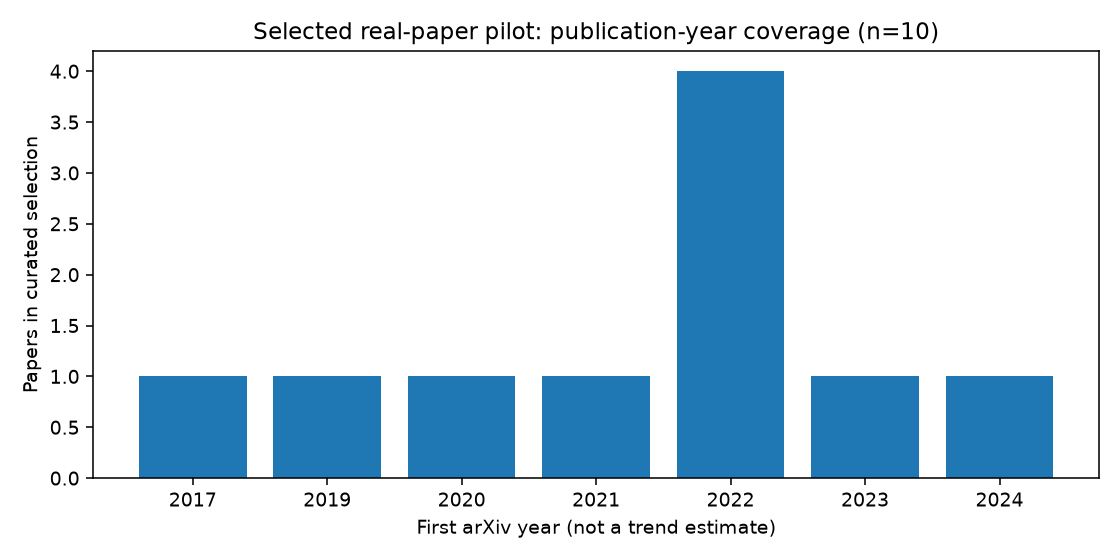

,rank,title,source_url,retrieval_score
0,1,Are Transformers Effective for Time Series For...,https://arxiv.org/abs/2205.13504,11.264588
1,2,FEDformer: Frequency Enhanced Decomposed Trans...,https://arxiv.org/abs/2201.12740,3.346260
2,3,Informer: Beyond Efficient Transformer for Lon...,https://arxiv.org/abs/2012.07436,2.330407
3,4,TimeMixer: Decomposable Multiscale Mixing for ...,https://arxiv.org/abs/2405.14616,1.912725
4,5,Autoformer: Decomposition Transformers with Au...,https://arxiv.org/abs/2106.13008,1.781179


No nDCG or F1 is computed: there are no judged relevance labels for this curated selection.


In [57]:
# Plot metadata coverage and inspect sample retrieval ranks (not accuracy metrics).
from IPython.display import Image, display
case_png = real_case / 'publication_year_coverage.png'
if case_png.is_file():
    display(Image(filename=str(case_png)))
retrieval_pilot = pd.read_csv(real_case / 'retrieval_rankings_unjudged.csv')
display(retrieval_pilot.query('query_id == "q01" and retriever == "BM25"').head(5)[
    ['rank','title','source_url','retrieval_score']])
print('No nDCG or F1 is computed: there are no judged relevance labels for this curated selection.')

## Official Benchmark — BEIR SciFact (full held-out test)

This section never treats demo scores as scientific evidence. An official measurement requires the **upstream MD5-verified SciFact ZIP**, all **5,183** articles and **300** test claims with original relevance judgments. Run `python scripts/run_official_evaluation.py --download-scifact` in the complete project on an Internet-connected machine. A QASPER extractive token-F1 experiment is a *proxy*, not the official answer/evidence score. See `docs/OFFICIAL_BENCHMARK_PROTOCOL.md` for exact methodology and references.

In [58]:
# Show only measurements saved by the verified full-data evaluation runner.
from pathlib import Path
import json
from IPython.display import display, Markdown

OFFICIAL_DIR = ROOT / 'reports/official_evaluation/scifact'
status_file = OFFICIAL_DIR / 'EXECUTION_STATUS.json'
result_file = OFFICIAL_DIR / 'OFFICIAL_EVALUATION_RESULT.json'
if status_file.is_file() and json.loads(status_file.read_text(encoding='utf-8')).get('scifact_status') != 'COMPLETED_FULL_OFFICIAL_SCIFACT_TEST':
    _status = json.loads(status_file.read_text(encoding='utf-8'))
    print('Official benchmark:', _status.get('scifact_status'))
    print('Reason:', _status.get('scifact_error','The latest evaluation was not completed.'))
    if result_file.is_file():
        print('A previous result exists but is NOT the latest validated execution.')
elif result_file.is_file():
    official = json.loads(result_file.read_text(encoding='utf-8'))
    print('Saved benchmark status:', official.get('evaluation_status'))
    print('Dataset source:', official.get('dataset_source'))
    display(pd.DataFrame(official.get('metrics_at_10') or [])[
        ['model','n_queries','ndcg','recall','mrr','precision']])
    if (ROOT/'data/raw/scifact/OFFICIAL_DATASET_MANIFEST.json').is_file():
        from research_intelligence.official_scifact import validate_scifact
        print('Re-checked dataset:', validate_scifact(ROOT/'data/raw/scifact')['official_archive_verified'])
    else:
        print('Dataset not currently present; saved values cannot be independently rechecked in this kernel.')
elif status_file.is_file():
    status = json.loads(status_file.read_text(encoding='utf-8'))
    print('Official benchmark:', status.get('scifact_status'))
    print('Reason:', status.get('scifact_error','No verified score has been generated.'))
else:
    print('OFFICIAL_SCIFACT_NOT_RUN: No measured results supplied. This is not a notebook error.')
print('To run: python scripts/run_official_evaluation.py --download-scifact')

Saved benchmark status: COMPLETED_FULL_OFFICIAL_SCIFACT_TEST
Dataset source: https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/scifact.zip


,model,n_queries,ndcg,recall,mrr,precision
0,bm25,300,0.664660,0.784944,0.632780,0.087000
1,tfidf,300,0.595804,0.743833,0.553384,0.082000
2,title_bm25,300,0.571186,0.684833,0.543372,0.075667


Re-checked dataset: True
To run: python scripts/run_official_evaluation.py --download-scifact


### Actual SciFact + QASPER LLM Evaluation (external data, opt-in)

The complete repository includes an independently executable empirical study runner.
Its **official SciFact retrieval** stage verifies the original BEIR ZIP and held-out qrels.
Its **QASPER** stage uses a real local Ollama LLM with full-paper paragraph retrieval
and human-written reference answers held out from prompts. It reports answer token-F1,
exact match, abstention and citation-ID validity **proxies**, not official QASPER
leaderboard results or human factuality judgments.

From the full project root on a Windows PC with Internet and Ollama installed:

```powershell
ollama pull qwen2.5:7b
.\.venv\Scripts\python.exe scripts/run_empirical_study.py --download-scifact --download-qasper --ollama-model qwen2.5:7b --confirm-local-llm --qasper-questions 0
```

Use `--only-retrieval` to measure SciFact first, or `--qasper-questions 25` for an explicitly
**partial** and faster QASPER pilot. A notebook **Run All** does not silently download
models or execute hours of inference. The cell below reads the **observed outputs only**.


In [59]:
# Display measured external results only; no downloads or LLM calls are triggered.
import json
from pathlib import Path
from IPython.display import display

v15_empirical_status = ROOT / 'reports/empirical/EXECUTION_STATUS.json'
if v15_empirical_status.is_file():
    check = json.loads(v15_empirical_status.read_text(encoding='utf-8'))
    print('Official SciFact:', check.get('retrieval', 'NOT_REQUESTED'))
    print('Real LLM / QASPER:', check.get('llm', 'NOT_REQUESTED'))
    print('Combined study:', check.get('overall', 'INCOMPLETE'))
    for step in check.get('errors', []):
        print('Blocker:', step.get('stage'), step.get('error'))
    sci = ROOT / Path(check.get('retrieval_results','')) if check.get('retrieval_results') else None
    if sci and sci.is_file() and check.get('retrieval')=='COMPLETED_FULL_OFFICIAL_SCIFACT_TEST':
        scores = json.loads(sci.read_text(encoding='utf-8'))
        print('Measured SciFact results:')
        display(pd.DataFrame(scores.get('metrics_at_10') or []))
    llm = ROOT / Path(check.get('llm_results','')) if check.get('llm_results') else None
    if llm and llm.is_file() and str(check.get('llm','')).startswith('COMPLETED_'):
        scores = json.loads(llm.read_text(encoding='utf-8'))
        print('Measured local LLM answer F1 proxy:', scores.get('mean_token_f1_best_reference_proxy'))
        print('Actual successful model responses:', scores.get('successful_model_calls'))
        print('Not official QASPER scorer:', not scores.get('is_official_qasper_scorer'))
else:
    print('EMPIRICAL_STUDY_NOT_RUN: Use scripts/run_empirical_study.py with official data and local Ollama.')


Official SciFact: COMPLETED_FULL_OFFICIAL_SCIFACT_TEST
Real LLM / QASPER: COMPLETED_FULL_QASPER_REAL_LLM_PROXY_EVALUATION
Combined study: COMPLETED_REQUESTED_FULL_EVALUATIONS
Measured SciFact results:


,model,k,n_queries,ndcg,recall,mrr,precision,mean_query_latency_ms,index_build_seconds
0,bm25,10,300,0.664660,0.784944,0.632780,0.087000,16.794364,0.317744
1,tfidf,10,300,0.595804,0.743833,0.553384,0.082000,6.026576,1.396446
2,title_bm25,10,300,0.571186,0.684833,0.543372,0.075667,22.463613,0.364338


Measured local LLM answer F1 proxy: 0.3026380811510697
Actual successful model responses: 1451
Not official QASPER scorer: True


### Measured results supplied from the completed Windows experiment (2026-11-03)

The official SciFact retrieval and real Ollama QASPER test runs are **complete** in the saved report summaries. These are independent of the synthetic demonstration earlier in the notebook. The verified metrics are visualized below without downloading datasets or calling an LLM. Raw source datasets and per-query/per-answer predictions are **not** bundled, so these saved aggregate numbers cannot be independently recomputed here. QASPER metrics remain *unofficial lexical proxies*, not claim-level factuality or the official leaderboard scorer.


In [60]:
# Display the observed full-test measurements packaged with this project.
from IPython.display import display, Markdown, Image
from pathlib import Path
import json
import pandas as pd

empirical_root = ROOT / 'reports/empirical'
sci_json = ROOT / 'reports/official_evaluation/scifact/OFFICIAL_EVALUATION_RESULT.json'
qasper_json = empirical_root / 'qasper/qwen2.5_7b_full/LLM_EVALUATION_RESULT.json'
if sci_json.is_file() and qasper_json.is_file():
    measured_sci = json.loads(sci_json.read_text(encoding='utf-8'))
    measured_llm = json.loads(qasper_json.read_text(encoding='utf-8'))
    assert measured_sci.get('evaluation_status') == 'COMPLETED_FULL_OFFICIAL_SCIFACT_TEST'
    assert measured_llm.get('status') == 'COMPLETED_FULL_QASPER_REAL_LLM_PROXY_EVALUATION'
    assert measured_llm.get('successful_model_calls') == measured_llm.get('selected_questions')
    display(Markdown('**BEIR SciFact — observed nDCG@10, Recall@10 and MRR@10 (300 held-out test queries)**'))
    display(pd.DataFrame(measured_sci['metrics_at_10'])[['model', 'ndcg', 'recall', 'mrr', 'precision']].round(4))
    display(Markdown('**QASPER — real Qwen2.5:7b, unofficial answer-overlap proxies (1,451 test questions)**'))
    display(pd.DataFrame([{
        'successful_answers': measured_llm['successful_model_calls'],
        'failed_questions': measured_llm['failed_questions'],
        'first_reference_token_f1': measured_llm['mean_token_f1_first_reference_proxy'],
        'best_reference_token_f1': measured_llm['mean_token_f1_best_reference_proxy'],
        'best_reference_exact_match': measured_llm['mean_exact_match_best_reference_proxy'],
        'valid_citation_id_fraction': measured_llm['valid_citation_id_fraction_proxy'],
    }]).round(4))
    for plot in ['01_scifact_ndcg10.png', '03_qasper_answer_proxy_metrics.png', '04_qasper_citation_id_validity.png']:
        f = empirical_root / 'figures' / plot
        if f.is_file(): display(Image(filename=str(f)))
    print('Measured benchmark summaries: reports/empirical/EMPIRICAL_RESULTS_REPORT.md')
    print('Citation ID validity is NOT scientific claim factuality.')
else:
    print('MEASURED_RESULTS_NOT_PACKAGED: execute the full empirical runner first.')


**BEIR SciFact — observed nDCG@10, Recall@10 and MRR@10 (300 held-out test queries)**

,model,ndcg,recall,mrr,precision
0,bm25,0.6647,0.7849,0.6328,0.0870
1,tfidf,0.5958,0.7438,0.5534,0.0820
2,title_bm25,0.5712,0.6848,0.5434,0.0757


**QASPER — real Qwen2.5:7b, unofficial answer-overlap proxies (1,451 test questions)**

,successful_answers,failed_questions,first_reference_token_f1,best_reference_token_f1,best_reference_exact_match,valid_citation_id_fraction
0,1451,0,0.2245,0.3026,0.0813,0.8387


Measured benchmark summaries: reports/empirical/EMPIRICAL_RESULTS_REPORT.md
Citation ID validity is NOT scientific claim factuality.


## 23 · Evidence-Based Submission Audit & Final Research Results

This section checks observed inputs and outputs, not whether files merely exist. Missing real experiments remain **PENDING**.

In [61]:
# Validate real paper provenance, observed model scores, and human-reviewed evidence.
from research_intelligence.release_audit import write_release_report
from research_intelligence.observed_results import summarize_observed_results

release = write_release_report(ROOT)
observed = summarize_observed_results(ROOT)
display(pd.DataFrame([
    {'evidence': name, 'status': detail['status'], 'observed': detail['observed']}
    for name, detail in release['gates'].items()
]))
print('Submission verdict:', release['verdict'])
print('Evidence gates:', release['passed_gates'], '/', release['total_gates'])
print('Observed research figures:', observed['plots'] or 'PENDING real results')
print('Saved reports:', ROOT / 'reports/generated/SUBMISSION_STATUS.md',
      ROOT / 'reports/generated/OBSERVED_RESEARCH_RESULTS.md')

,evidence,status,observed
0,Real arXiv corpus,PENDING,0 attributed papers; provenance verified=False
1,Aligned full-text evidence,PENDING,"0 papers, 0 valid passages, 0 unmatched IDs"
2,Reviewed experimental results,PENDING,0 reviewer-approved results across 0 corpus pa...
3,Official SciFact benchmark,PARTIAL,"300 official test claims, original ZIP and fil..."
4,QASPER LLM QA evaluation,PENDING,0 predictions; scored=0; generator=not available
5,Actual grounded LLM synthesis,PENDING,0 cited claims; status=not run
6,Independent claim verification,PENDING,0 human-reviewed model predictions


Submission verdict: PROTOTYPE_ONLY_REAL_RESULTS_INCOMPLETE
Evidence gates: 0 / 7
Observed research figures: PENDING real results
Saved reports: I:\Potforlio\Advanced LLM Scientific Research System\reports\generated\SUBMISSION_STATUS.md I:\Potforlio\Advanced LLM Scientific Research System\reports\generated\OBSERVED_RESEARCH_RESULTS.md


In [62]:
# Compare actual RAG runs only when measured results exist.
path = ROOT / 'results/rag_comparison.jsonl'
if path.is_file() and path.stat().st_size:
    experiment = pd.read_json(path, lines=True)
    required = {'model', 'retrieval_method', 'response_format_ok', 'latency_ms'}
    if required.issubset(experiment.columns):
        cols = ['response_format_ok', 'latency_ms']
        display(experiment.groupby(['model', 'retrieval_method'])[cols].mean().round(3))
    else:
        print('Invalid RAG result schema:', sorted(required - set(experiment.columns)))
else:
    print('NOT RUN: No measured RAG results; no quality claims are possible.')


NOT RUN: No measured RAG results; no quality claims are possible.


### Publication and evaluation limits

The **BEIR SciFact full-test lexical ranking evaluation** and **QASPER full-test real local Qwen2.5:7b answer generation + proxy scoring** are completed in the saved external benchmark summaries, *independent of the synthetic demonstration*. The original upstream dataset files, per-query results and per-answer model traces are not bundled with this GitHub ZIP; release scores were summarized from the provided Windows run. The QASPER proxies are **not** official leaderboard metrics or independent human fact-checking.

The additional seven-gate scientific evidence audit includes PDF-grounded arXiv source alignment, reviewer-approved experimental tables, independent human claim support annotation and other requirements that have **not** been completed by the two measured benchmarks alone. A pending strict audit is not a contradiction of completed SciFact and QASPER evaluations. Do not report incomplete gates as validated.

Disclose earlier collaborative group-project contributions accurately, and preserve the dataset checksums, experiment configuration and user-provided source result snapshots.
